<a href="https://colab.research.google.com/github/vaidysrm-gitub/TMDB-Analystics/blob/main/4_TMDB_Movie_Visualization_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set chart style
sns.set_style("whitegrid")

# Set chart size
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
from google.colab import files

uploaded = files.upload()
print("All CSV files loaded successfully")

Saving movie_genres.csv to movie_genres.csv
Saving movies.csv to movies.csv
Saving movies_keywords.csv to movies_keywords.csv
Saving cast.csv to cast.csv
Saving crew.csv to crew.csv
Saving genres.csv to genres.csv
All CSV files loaded successfully


In [3]:
movies = pd.read_csv("movies.csv")
genres = pd.read_csv("genres.csv")
movie_genres = pd.read_csv("movie_genres.csv")
cast = pd.read_csv("cast.csv")
crew = pd.read_csv("crew.csv")
movie_keywords = pd.read_csv("movies_keywords.csv")

In [4]:
movies.head()

,movie_id,title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,status,overview
0,157336,Interstellar,en,2014-11-05,169,165000000.0,7.466067e+08,73.0452,8.484,40566,Released,The adventures of a group of explorers who mak...
1,27205,Inception,en,2010-07-15,148,160000000.0,8.390306e+08,55.8497,8.400,39727,Released,"Cobb, a skilled thief who commits corporate es..."
2,24428,The Avengers,en,2012-04-25,143,220000000.0,1.518816e+09,72.2515,8.062,38993,Released,When an unexpected enemy emerges and threatens...
3,155,The Dark Knight,en,2008-07-16,152,185000000.0,1.004558e+09,60.5510,8.534,36255,Released,Batman raises the stakes in his war on crime. ...
4,19995,Avatar,en,2009-12-16,162,237000000.0,2.923706e+09,48.1996,7.610,34348,Released,"In the 22nd century, a paraplegic Marine is di..."


In [5]:
print(movies.columns)

Index(['movie_id', 'title', 'original_language', 'release_date', 'runtime',
       'budget', 'revenue', 'popularity', 'vote_average', 'vote_count',
       'status', 'overview'],
      dtype='object')


In [6]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2503 entries, 0 to 2502
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   movie_id           2503 non-null   int64  
 1   title              2503 non-null   object 
 2   original_language  2503 non-null   object 
 3   release_date       2503 non-null   object 
 4   runtime            2503 non-null   int64  
 5   budget             2503 non-null   float64
 6   revenue            2503 non-null   float64
 7   popularity         2503 non-null   float64
 8   vote_average       2503 non-null   float64
 9   vote_count         2503 non-null   int64  
 10  status             2503 non-null   object 
 11  overview           2503 non-null   object 
dtypes: float64(4), int64(3), object(5)
memory usage: 234.8+ KB


In [7]:
# Convert columns into numeric format
#Prepare the data for visualization
numeric_columns = [
    "budget",
    "revenue",
    "runtime",
    "popularity",
    "vote_average",
    "vote_count"
]

for col in numeric_columns:
    movies[col] = pd.to_numeric(movies[col], errors="coerce")

# Convert release_date into datetime
movies["release_date"] = pd.to_datetime(
    movies["release_date"], errors="coerce"
)

# Create release year
movies["release_year"] = movies["release_date"].dt.year

print("Data preparation completed")

Data preparation completed


In [8]:
#Check missing values:
print(movies[numeric_columns].isnull().sum())

budget          0
revenue         0
runtime         0
popularity      0
vote_average    0
vote_count      0
dtype: int64


In [9]:
financial_movies = movies[
    (movies["budget"] > 0) &
    (movies["revenue"] > 0)
].copy()

print("Financial records:", len(financial_movies))

Financial records: 2503


# **Visualization Tasks**

# **Univariate - Distribution of movie budgets (histogram/KDE).**

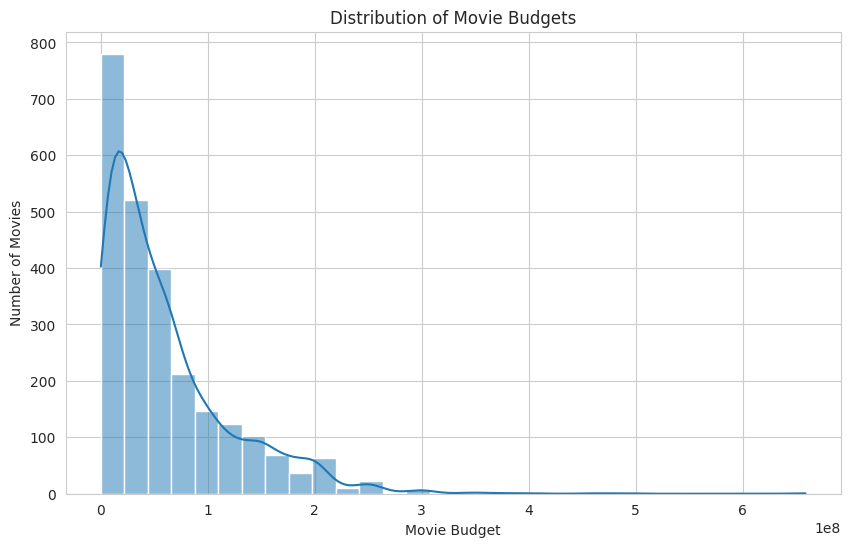

In [10]:
# Remove zero and missing budgets
budget_data = movies[movies["budget"] > 0]

plt.figure(figsize=(10, 6))

sns.histplot(
    data=budget_data,
    x="budget",
    bins=30,
    kde=True
)

plt.title("Distribution of Movie Budgets")
plt.xlabel("Movie Budget")
plt.ylabel("Number of Movies")

plt.show()

1. If most movies appear in the lower budget ranges, it indicates that the dataset contains more low-budget movies.

2. If a few movies appear at extremely high budget values, it indicates the presence of high-budget productions.

3. A long right tail indicates a positively skewed distribution.

# **Univariate – Distribution of Movie Runtimes(box plot/violin plot)**

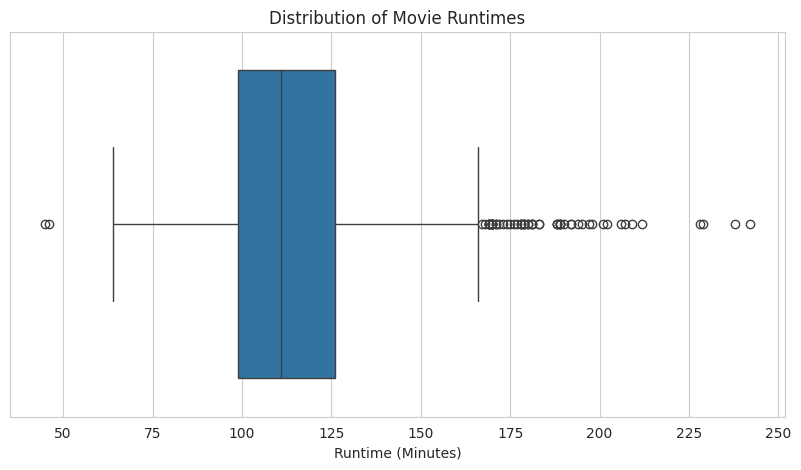

In [11]:
#Box plot
runtime_data = movies[movies["runtime"] > 0]

plt.figure(figsize=(10, 5))

sns.boxplot(
    x=runtime_data["runtime"]
)

plt.title("Distribution of Movie Runtimes")
plt.xlabel("Runtime (Minutes)")

plt.show()

1. The median shows the typical movie duration.

2. A wide box indicates greater variation in movie runtimes.

3. Outliers indicate movies that are unusually short or long compared with the majority.

# **Univariate - Distribution of vote_average scores (histogram).**

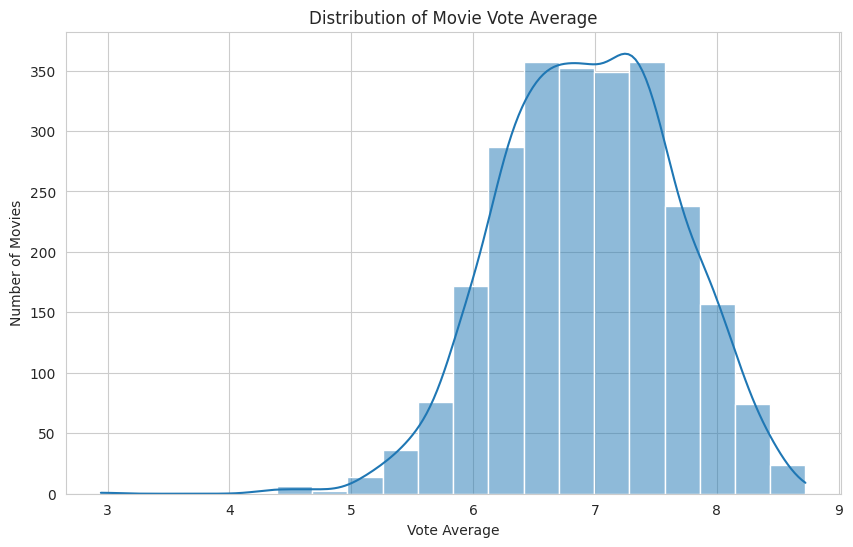

In [12]:
rating_data = movies[
    movies["vote_average"].notnull()
]

plt.figure(figsize=(10, 6))

sns.histplot(
    data=rating_data,
    x="vote_average",
    bins=20,
    kde=True
)

plt.title("Distribution of Movie Vote Average")
plt.xlabel("Vote Average")
plt.ylabel("Number of Movies")

plt.show()

1. A concentration around higher scores indicates that many movies receive favourable ratings.

2. A concentration around lower scores indicates that many movies receive less favourable ratings.

3. A wide distribution indicates considerable variation in audience opinions.

# **Univariate - Count of movies per genre (bar/count plot).**


In [13]:
#bar plot
genre_data = movie_genres.merge(
    genres,
    on="genre_id",
    how="inner"
)

print(genre_data.head())

   movie_id  genre_id       genre_name
0    157336        12        Adventure
1    157336        18            Drama
2    157336       878  Science Fiction
3     27205        28           Action
4     27205       878  Science Fiction


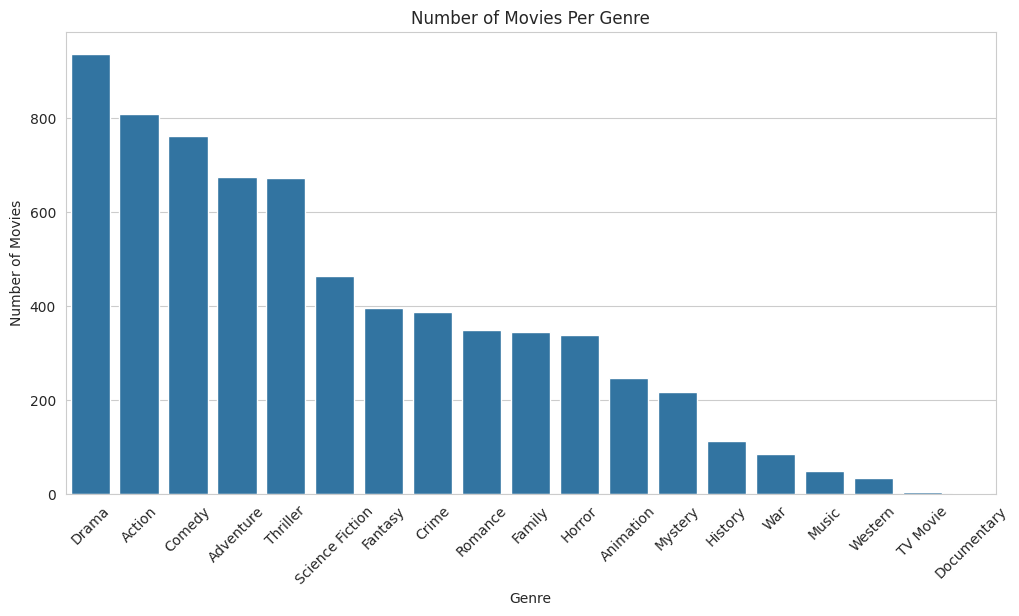

In [14]:
genre_counts = genre_data["genre_name"].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.index,
    y=genre_counts.values
)

plt.title("Number of Movies Per Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")

plt.xticks(rotation=45)

plt.show()

1. Genres with taller bars have more movie entries.

2. Genres with shorter bars have fewer movie entries.

3. This helps identify the most frequently represented genres in the dataset.

# **Bivariate - Budget vs revenue (scatter plot, with trend line).**


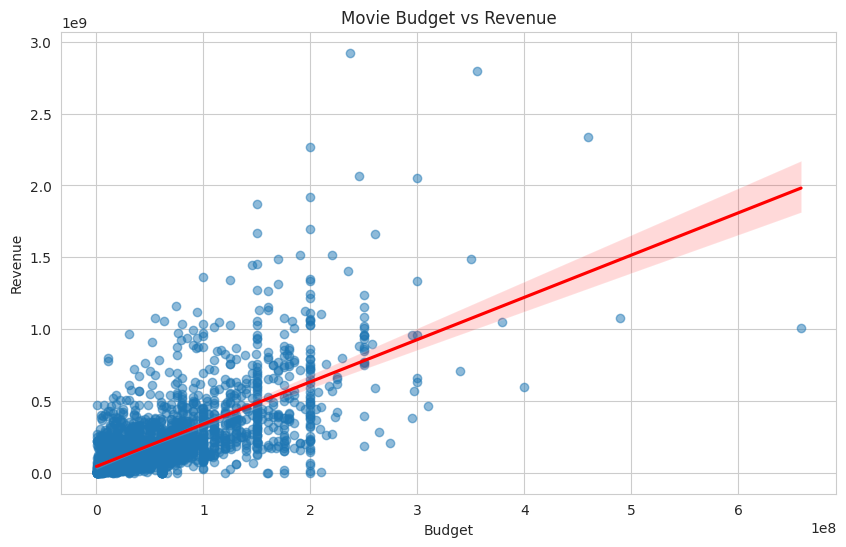

In [15]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=financial_movies,
    x="budget",
    y="revenue",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.show()

1. If the trend line slopes upwards, higher-budget movies tend to generate higher revenue.

2. If points are widely scattered, budget alone does not explain revenue.

3. Movies far above the trend line generate more revenue than the overall trend would suggest.

4. Movies below the trend line generate less revenue than expected.

# **Bivariate - Popularity vs vote count (scatter plot).**

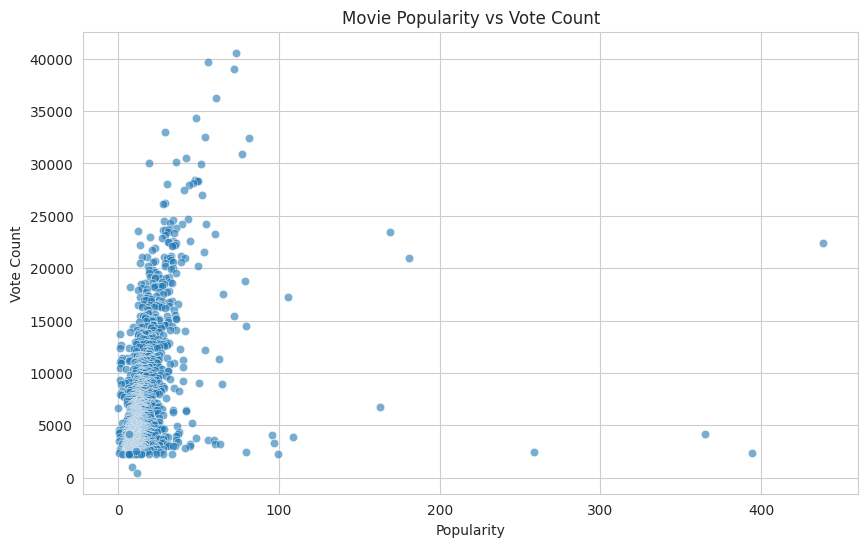

In [16]:
popularity_data = movies[
    (movies["popularity"] >= 0) &
    (movies["vote_count"] > 0)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=popularity_data,
    x="popularity",
    y="vote_count",
    alpha=0.6
)

plt.title("Movie Popularity vs Vote Count")
plt.xlabel("Popularity")
plt.ylabel("Vote Count")

plt.show()

1. Points concentrated in the lower-left region indicate movies with lower popularity and fewer votes.

2. Points in the upper-right region indicate movies with higher popularity and more votes.

3. Some movies may have high popularity but relatively fewer votes.

4. A positive relationship suggests that popular movies tend to attract more audience participation.

# **Bivariate - Average rating by genre (bar chart).**

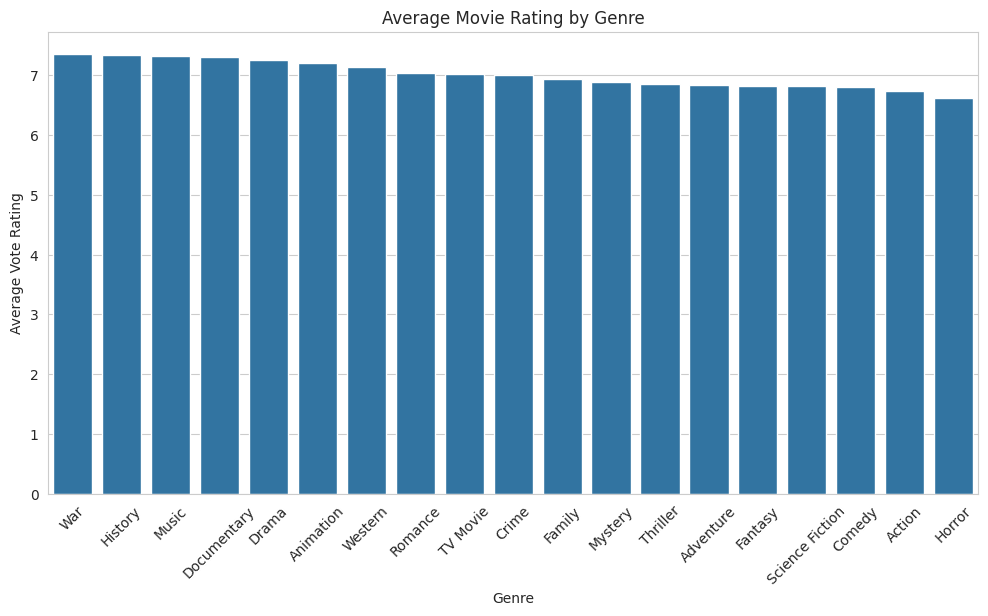

In [17]:
rating_genre = movie_genres.merge(
    genres,
    on="genre_id",
    how="inner"
)

rating_genre = rating_genre.merge(
    movies[["movie_id", "vote_average"]],
    on="movie_id",
    how="inner"
)

avg_rating = rating_genre.groupby(
    "genre_name"
)["vote_average"].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=avg_rating.index,
    y=avg_rating.values
)

plt.title("Average Movie Rating by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Vote Rating")

plt.xticks(rotation=45)

plt.show()

1. Genres with higher bars receive higher average audience ratings.

2. Genres with lower bars receive comparatively lower average ratings.

3. Comparing genres helps identify differences in audience reception.

# **Bivariate - Number of movies released per year (bar/column chart).**

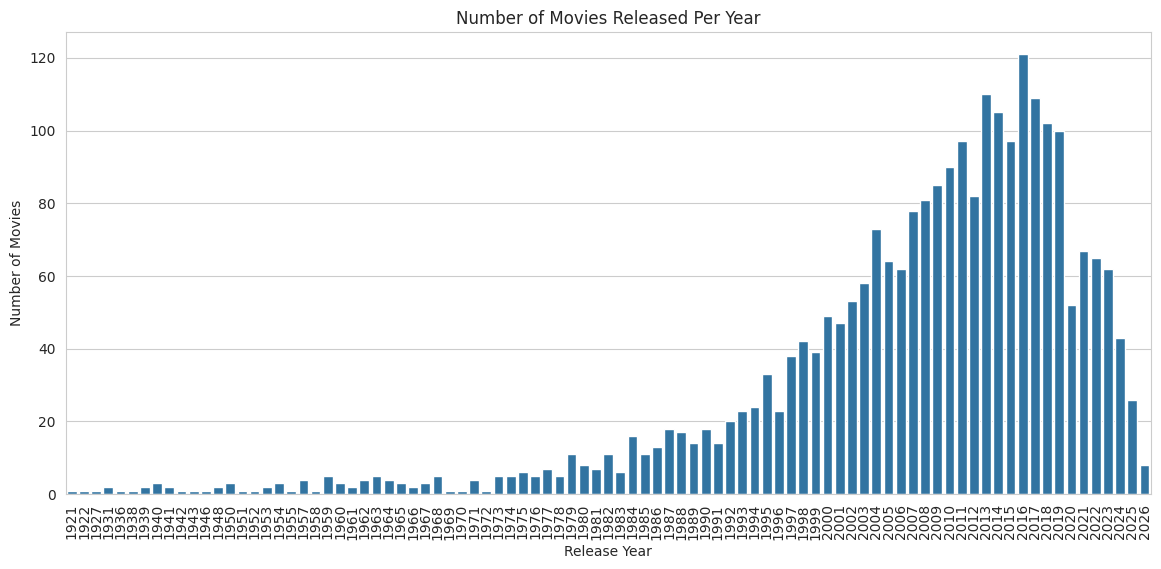

In [18]:
#column chart

year_counts = movies[
    movies["release_year"].notnull()
].groupby("release_year")["movie_id"].nunique()

plt.figure(figsize=(14, 6))

sns.barplot(
    x=year_counts.index,
    y=year_counts.values
)

plt.title("Number of Movies Released Per Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")

plt.xticks(rotation=90)

plt.show()

1. Increasing bar heights indicate an increase in recorded movie releases.

2. Decreasing bar heights indicate fewer recorded releases.

3. Sudden changes may indicate changes in the dataset's coverage or actual production trends.

4. Recent years may have incomplete data.

# **Multivariate - Correlation heatmap of budget, revenue, runtime, popularity, vote_average and vote_count (heatmap).**

In [19]:
# Join movie_genres and genres
primary_genre_data = movie_genres.merge(
    genres,
    on="genre_id",
    how="inner"
)

# Select first available genre for each movie
primary_genre_data = primary_genre_data.drop_duplicates(
    subset="movie_id",
    keep="first"
)

# Rename genre column
primary_genre_data = primary_genre_data[
    ["movie_id", "genre_name"]
].rename(columns={
    "genre_name": "primary_genre"
})

# Join primary genre with movies
movie_analysis = movies.merge(
    primary_genre_data,
    on="movie_id",
    how="left"
)

print(movie_analysis.head())

   movie_id            title original_language release_date  runtime  \
0    157336     Interstellar                en   2014-11-05      169   
1     27205        Inception                en   2010-07-15      148   
2     24428     The Avengers                en   2012-04-25      143   
3       155  The Dark Knight                en   2008-07-16      152   
4     19995           Avatar                en   2009-12-16      162   

        budget       revenue  popularity  vote_average  vote_count    status  \
0  165000000.0  7.466067e+08     73.0452         8.484       40566  Released   
1  160000000.0  8.390306e+08     55.8497         8.400       39727  Released   
2  220000000.0  1.518816e+09     72.2515         8.062       38993  Released   
3  185000000.0  1.004558e+09     60.5510         8.534       36255  Released   
4  237000000.0  2.923706e+09     48.1996         7.610       34348  Released   

                                            overview  release_year  \
0  The adventure

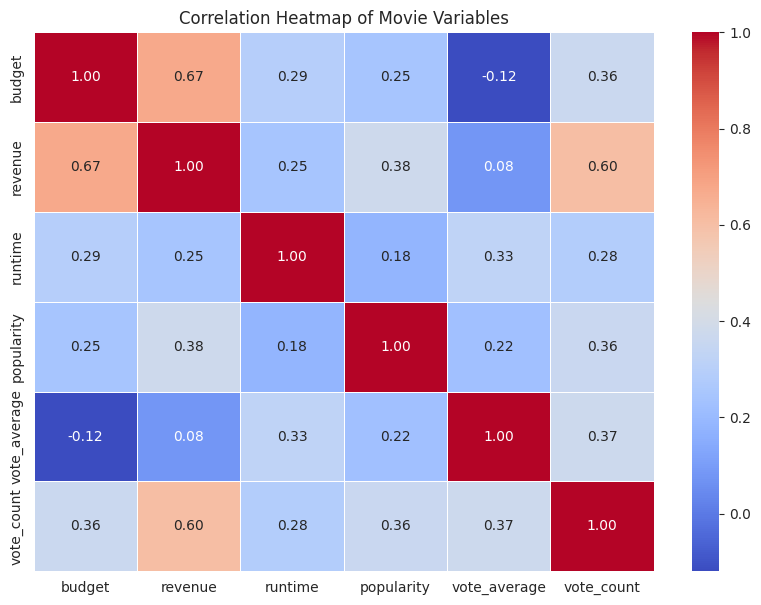

In [20]:
#Chart type: Correlation Heatmap.
corr_data = movies[
    [
        "budget",
        "revenue",
        "runtime",
        "popularity",
        "vote_average",
        "vote_count"
    ]
].copy()

# Treat zero budget and revenue as unknown
corr_data.loc[corr_data["budget"] == 0, "budget"] = np.nan
corr_data.loc[corr_data["revenue"] == 0, "revenue"] = np.nan

# Calculate correlation
correlation = corr_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Movie Variables")

plt.show()

1. A positive correlation between budget and revenue suggests that higher-budget movies tend to generate higher revenue.

2. A positive correlation between popularity and vote count suggests that popular movies may attract more audience votes.

3. A correlation close to zero indicates a weak linear relationship.

4. A negative correlation indicates that two variables tend to move in opposite directions.

# **Multivariate - Pairplot of budget, revenue, popularity and vote_average, colored by primary genre (pairplot).**

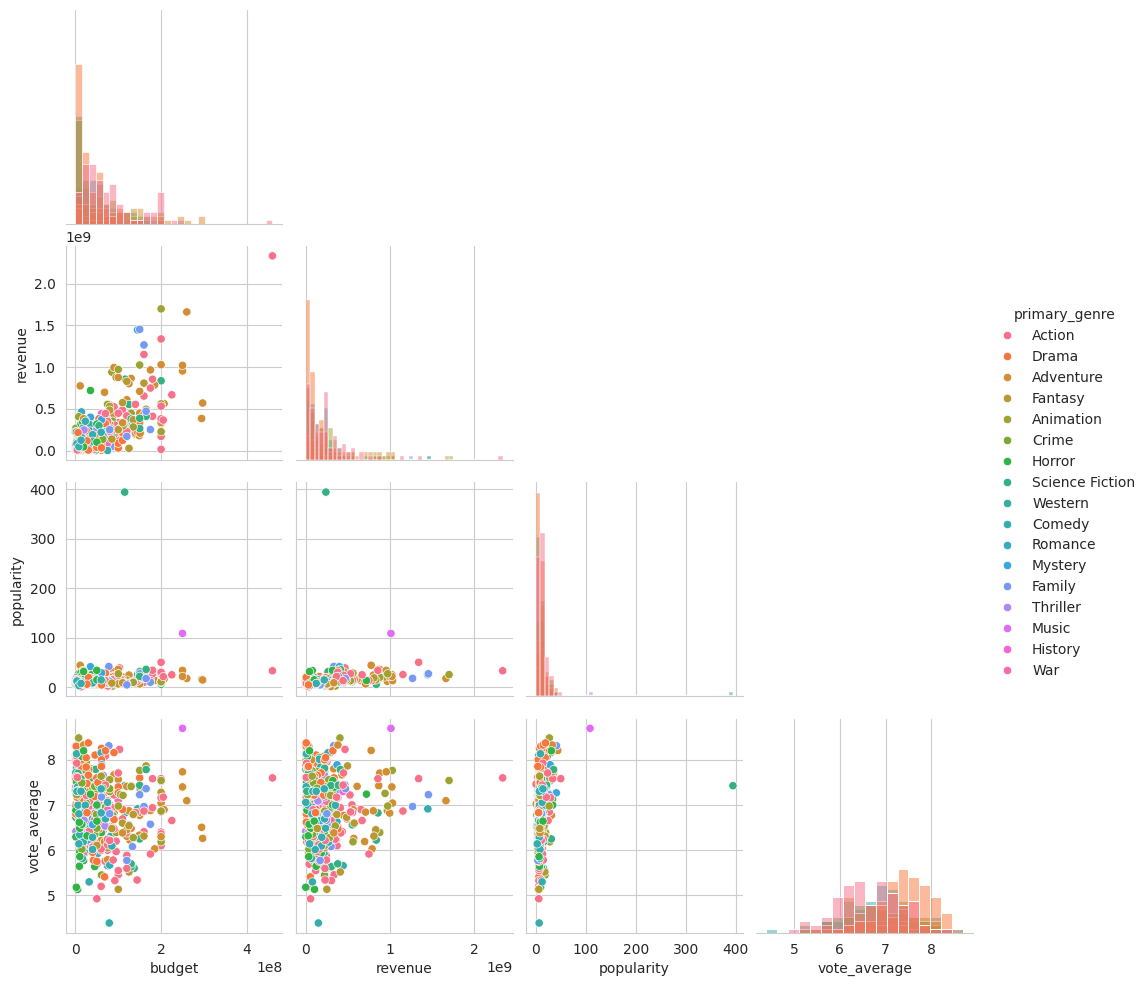

In [21]:
pair_data = movie_analysis[
    [
        "budget",
        "revenue",
        "popularity",
        "vote_average",
        "primary_genre"
    ]
].copy()

# Remove invalid financial values
pair_data = pair_data[
    (pair_data["budget"] > 0) &
    (pair_data["revenue"] > 0)
]

# Remove missing values
pair_data = pair_data.dropna()

# Select a sample to make the chart easier to display
pair_data = pair_data.sample(
    n=min(500, len(pair_data)),
    random_state=42
)

sns.pairplot(
    pair_data,
    vars=[
        "budget",
        "revenue",
        "popularity",
        "vote_average"
    ],
    hue="primary_genre",
    diag_kind="hist",
    corner=True
)

plt.show()

1. Budget and revenue scatter plots help identify whether higher investments are associated with higher earnings across genres.

2. Popularity and vote average plots help compare audience interest and ratings.

3. Different genre colours help identify whether certain genres form distinct patterns.

4. Diagonal histograms reveal the distribution of each numerical variable.

# **Multivariate - Budget vs revenue colored by primary genre, with point size showing vote_count (scatter plot with hue and size).**

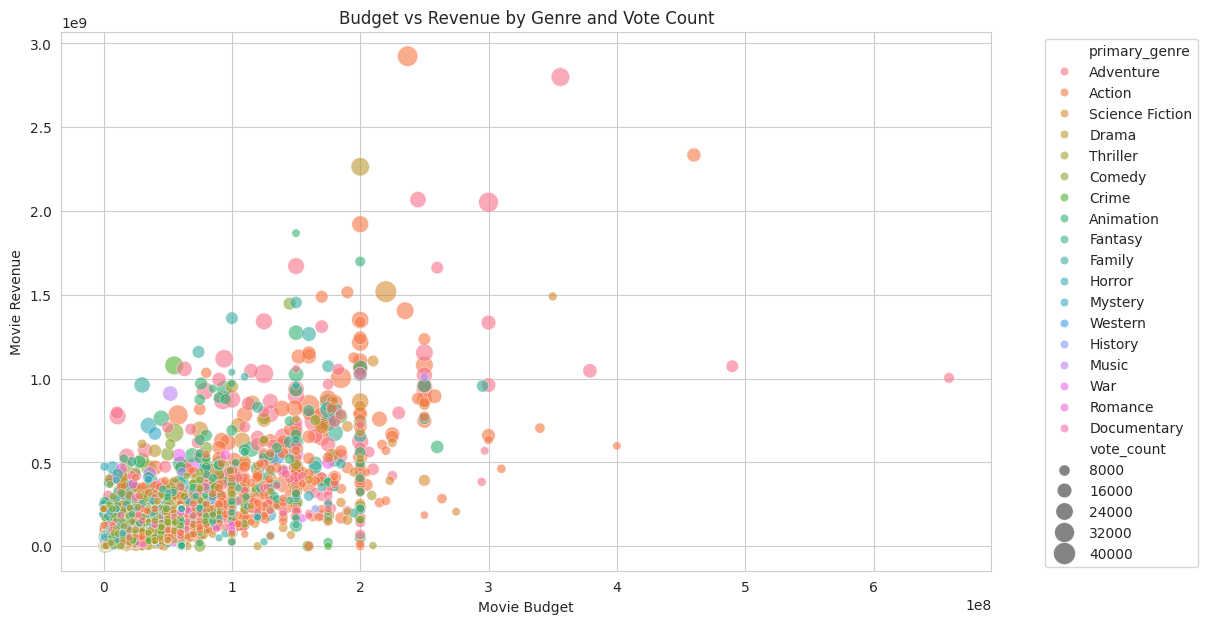

In [22]:
scatter_data = movie_analysis[
    [
        "budget",
        "revenue",
        "vote_count",
        "primary_genre"
    ]
].copy()

scatter_data = scatter_data[
    (scatter_data["budget"] > 0) &
    (scatter_data["revenue"] > 0) &
    (scatter_data["vote_count"] > 0)
]

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=scatter_data,
    x="budget",
    y="revenue",
    hue="primary_genre",
    size="vote_count",
    sizes=(20, 250),
    alpha=0.6
)

plt.title("Budget vs Revenue by Genre and Vote Count")
plt.xlabel("Movie Budget")
plt.ylabel("Movie Revenue")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.show()

1. Large circles in the upper-right area represent movies with high budgets, high revenue and high vote counts.

2. Different genre colours help identify financial patterns across genres.

3. Movies with high budgets but low revenue may indicate weaker financial performance.

4. Movies with lower budgets but higher revenue may indicate efficient investment.

# **Multivariate - Distribution of vote_average for each genre in separate panels (FacetGrid with histograms).**

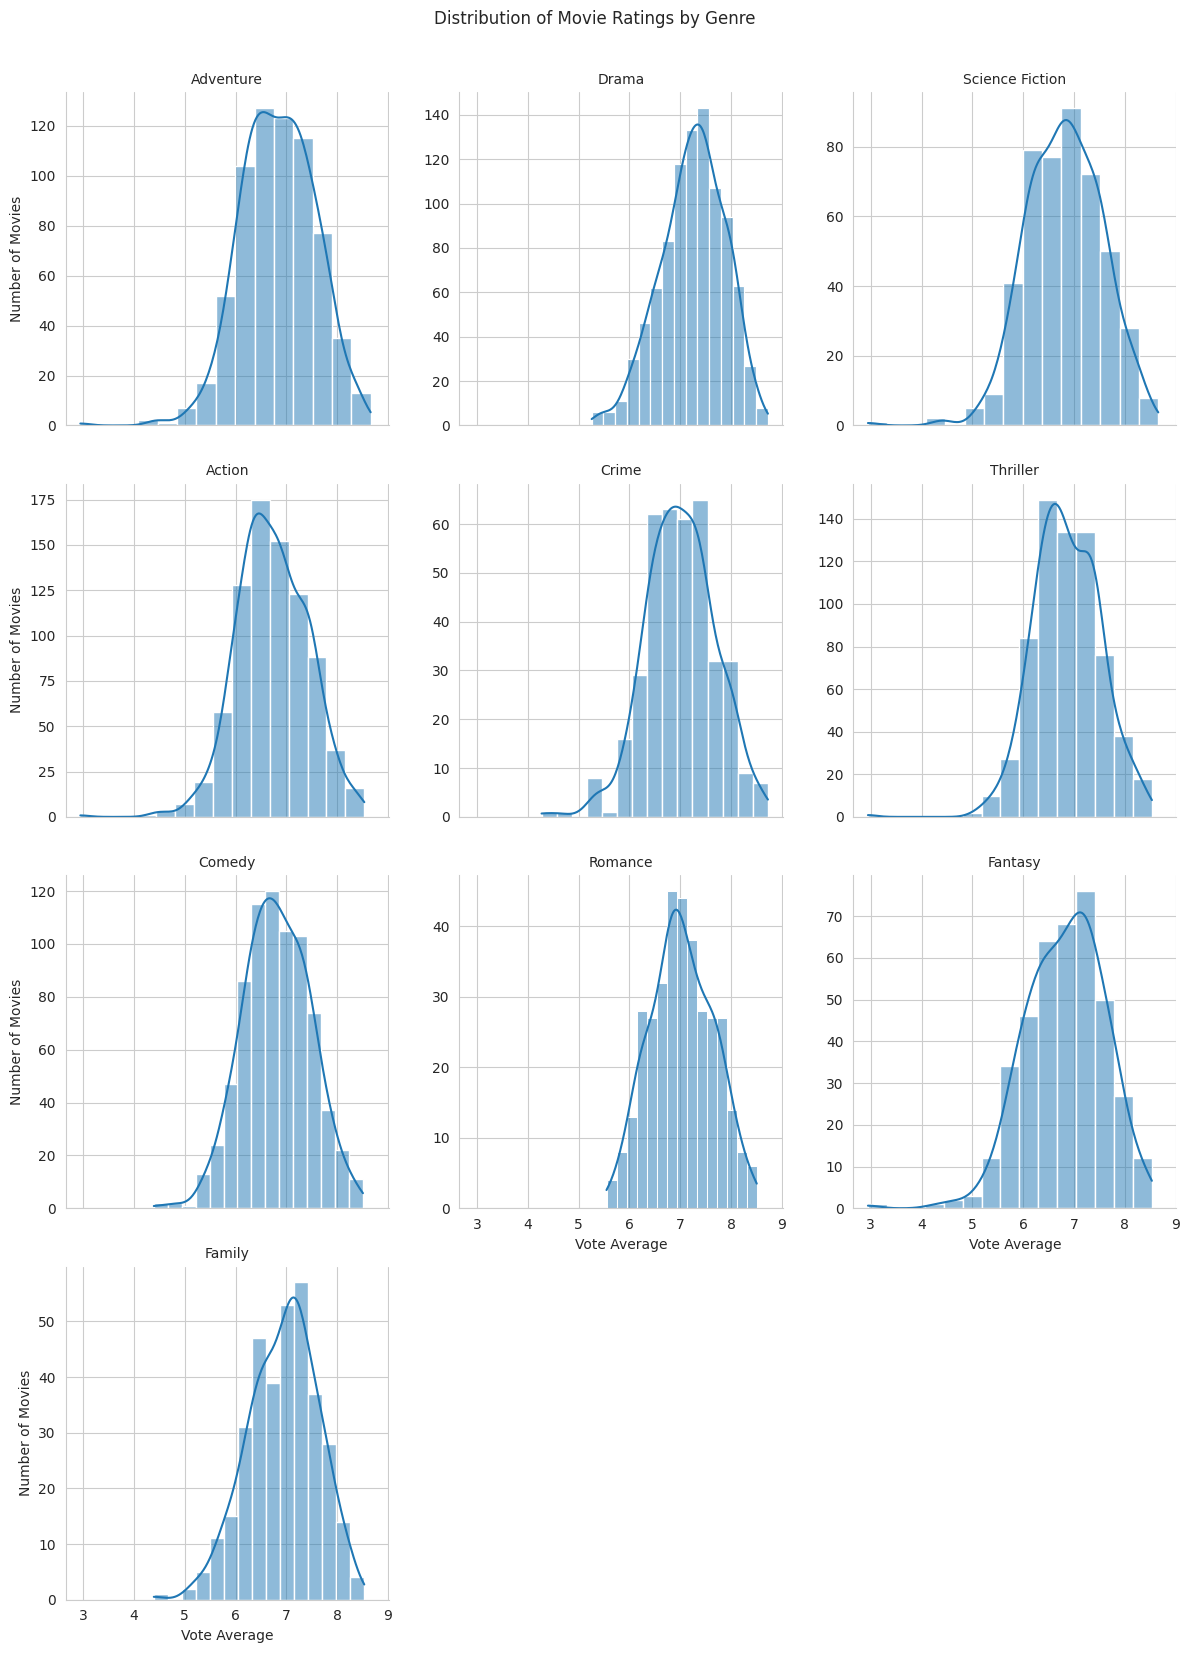

In [23]:
facet_data = rating_genre[
    ["movie_id", "vote_average", "genre_name"]
].dropna()

# Select the 10 genres with the most movie entries
top_genres = facet_data["genre_name"].value_counts().head(10).index

facet_data = facet_data[
    facet_data["genre_name"].isin(top_genres)
]

# Create separate panels
g = sns.FacetGrid(
    facet_data,
    col="genre_name",
    col_wrap=3,
    height=4,
    sharex=True,
    sharey=False
)

# Add histogram to each panel
g.map_dataframe(
    sns.histplot,
    x="vote_average",
    bins=15,
    kde=True
)

g.set_axis_labels(
    "Vote Average",
    "Number of Movies"
)

g.set_titles("{col_name}")

g.fig.suptitle(
    "Distribution of Movie Ratings by Genre",
    y=1.03
)

plt.show()

1. Genres with ratings concentrated at the higher end may have stronger audience reception.

2. Genres with ratings spread across a wider range show greater variation in audience opinions.

3. Comparing panels helps identify differences in rating patterns between genres.

4. Genres with a concentration of lower ratings may indicate comparatively weaker audience reception.

# **Multivariate - Average revenue by genre and release decade (heatmap of a pivot table).**

In [24]:
decade_data = movie_analysis.copy()

# Keep movies with valid revenue
decade_data = decade_data[
    (decade_data["revenue"] > 0) &
    (decade_data["release_year"].notnull()) &
    (decade_data["primary_genre"].notnull())
]

# Convert release year into decade
decade_data["release_decade"] = (
    (decade_data["release_year"] // 10) * 10
).astype(int)

print(
    decade_data[
        ["title", "release_year", "release_decade", "primary_genre", "revenue"]
    ].head()
)

             title  release_year  release_decade    primary_genre  \
0     Interstellar          2014            2010        Adventure   
1        Inception          2010            2010           Action   
2     The Avengers          2012            2010  Science Fiction   
3  The Dark Knight          2008            2000           Action   
4           Avatar          2009            2000           Action   

        revenue  
0  7.466067e+08  
1  8.390306e+08  
2  1.518816e+09  
3  1.004558e+09  
4  2.923706e+09  


In [25]:
revenue_pivot = decade_data.pivot_table(
    index="primary_genre",
    columns="release_decade",
    values="revenue",
    aggfunc="mean"
)

print(revenue_pivot)

release_decade        1920         1930          1940          1950  \
primary_genre                                                         
Action                 NaN          NaN           NaN  1.050000e+08   
Adventure              NaN   33754967.0           NaN           NaN   
Animation              NaN          NaN  1.273647e+08  6.031968e+07   
Comedy           5450000.0    3025000.0  1.100000e+07  1.610000e+07   
Crime                  NaN          NaN           NaN  1.176680e+05   
Documentary            NaN          NaN           NaN           NaN   
Drama            1350322.0  201193926.5  6.852261e+06  6.938674e+07   
Family                 NaN          NaN           NaN  2.636000e+08   
Fantasy                NaN  184925486.0           NaN  2.595561e+07   
History                NaN          NaN           NaN  1.640000e+08   
Horror             27964.0          NaN           NaN           NaN   
Music                  NaN          NaN           NaN           NaN   
Myster

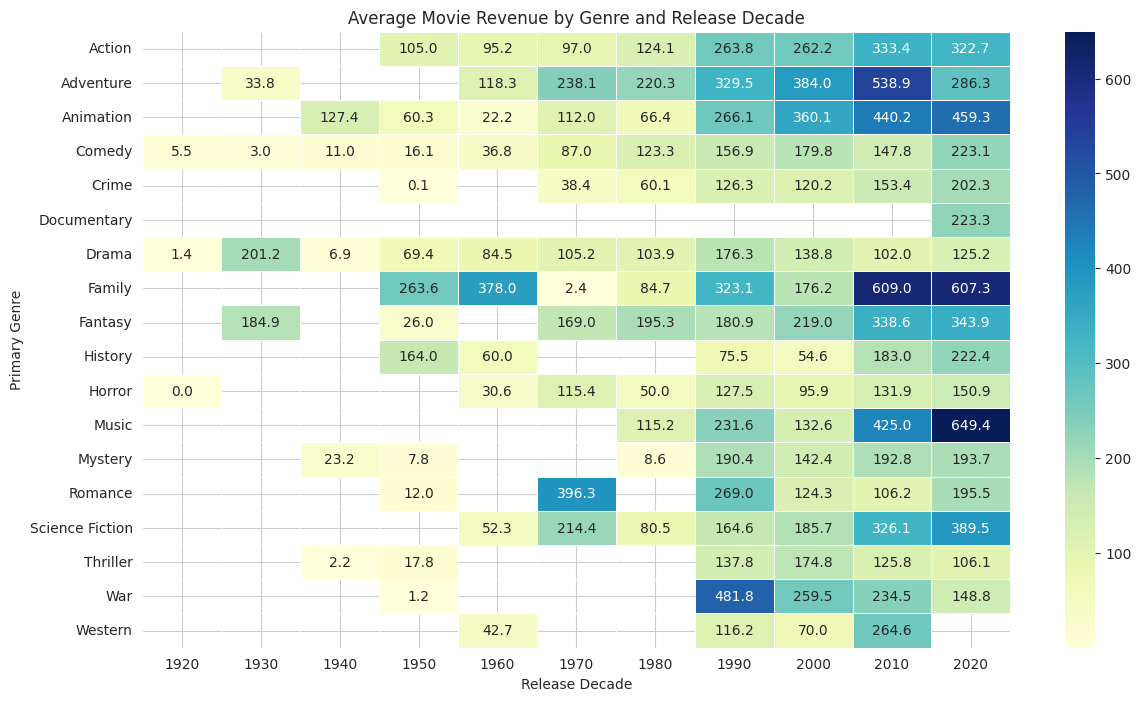

In [26]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    revenue_pivot / 1000000,
    annot=True,
    cmap="YlGnBu",
    fmt=".1f",
    linewidths=0.5
)

plt.title("Average Movie Revenue by Genre and Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("Primary Genre")

plt.show()

1. Genres with higher average revenue in a particular decade may indicate stronger financial performance during that period.

2. Comparing the same genre across decades helps identify changes in its revenue performance.

3. Comparing different genres within one decade helps identify which genres generated higher average revenue.

4. Empty cells indicate insufficient available records for that combination.